# Impacto de la lluvia en los tiempos de viaje al aeropuerto O'Hare (Chicago)

**Autora:** Daniela Salazar Canabal · Proyecto aprobado del bootcamp de Data Analytics de TripleTen

**Contexto:** Análisis para Zuber, una plataforma de viajes compartidos en Chicago, para entender los patrones de viaje y evaluar si el clima afecta la duración de los trayectos al aeropuerto.

**Contenido:**
1. Top 10 empresas de taxis por número de viajes
2. Top 10 barrios de destino
3. Prueba de hipótesis: ¿la lluvia cambia la duración de los viajes del Loop a O'Hare los sábados?

**Resultado principal:** la lluvia aumenta en 21% la duración de los viajes al aeropuerto (p-value = 6.74 × 10⁻¹²).

## Resumen de la revisión v1 <a class="tocSkip"></a>

<div class="alert alert-block alert-success">
<b>Comentario de Revisor            </b> <a class="tocSkip"></a>

Buen trabajo Daniela! Has completado correctamente todo lo necesario del notebook, realizaste un gran trabajo aplicando los conocimientos de analítica necesarios, se nota que los manejas muy bien. No tengo comentarios de corrección, tu proyecto está aprobado. Felicitaciones por completar el notebook en la primera revisión, mucho éxito en el siguiente sprint!

Saludos!

</div>

----

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

# Importar los archivos
df_companies = pd.read_csv('/datasets/project_sql_result_01.csv')
df_neighborhoods = pd.read_csv('/datasets/project_sql_result_04.csv')

# Estudiar los datos y verificar tipos
print(df_companies.info())
print(df_neighborhoods.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   company_name  64 non-null     object
 1   trips_amount  64 non-null     int64 
dtypes: int64(1), object(1)
memory usage: 1.1+ KB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   dropoff_location_name  94 non-null     object 
 1   average_trips          94 non-null     float64
dtypes: float64(1), object(1)
memory usage: 1.6+ KB
None


Diagnóstico de los Datos
df_companies: Tienes 64 empresas. Los tipos de datos son correctos (object para el nombre y int64 para la cantidad de viajes). No hay valores nulos.

df_neighborhoods: Tienes 94 barrios. Los tipos son correctos (object y float64). El promedio de viajes (average_trips) tiene decimales, lo cual es normal al ser una media.

In [11]:
# 3. Identificar los 10 principales barrios por finalización
top_10_neighborhoods = df_neighborhoods.sort_values(by='average_trips', ascending=False).head(10)
print(top_10_neighborhoods)

  dropoff_location_name  average_trips
0                  Loop   10727.466667
1           River North    9523.666667
2         Streeterville    6664.666667
3             West Loop    5163.666667
4                O'Hare    2546.900000
5             Lake View    2420.966667
6            Grant Park    2068.533333
7         Museum Campus    1510.000000
8            Gold Coast    1364.233333
9    Sheffield & DePaul    1259.766667


Diagnostico de los Datos
Top 10 Barrios: El Loop lidera con más de 10,000 viajes promedio, seguido muy de cerca por River North. Esto tiene sentido, ya que son las zonas comerciales y turísticas más densas de Chicago.

Se debe estar atento a la columna dropoff_location_name para asegurar que no haya nombres duplicados por errores de escritura (aunque a simple vista se ven limpios).

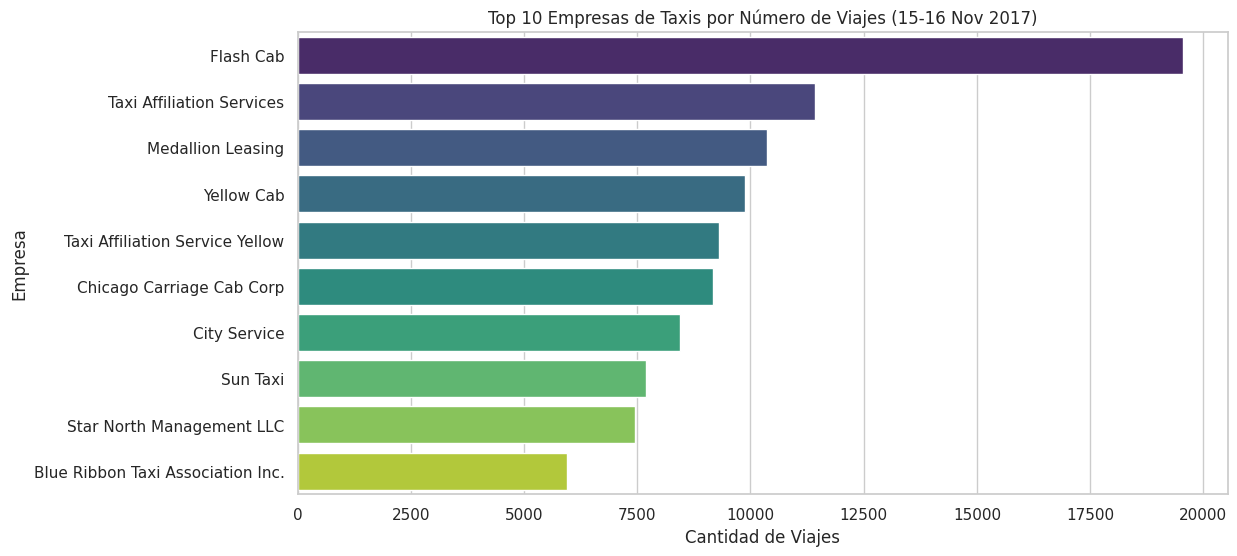

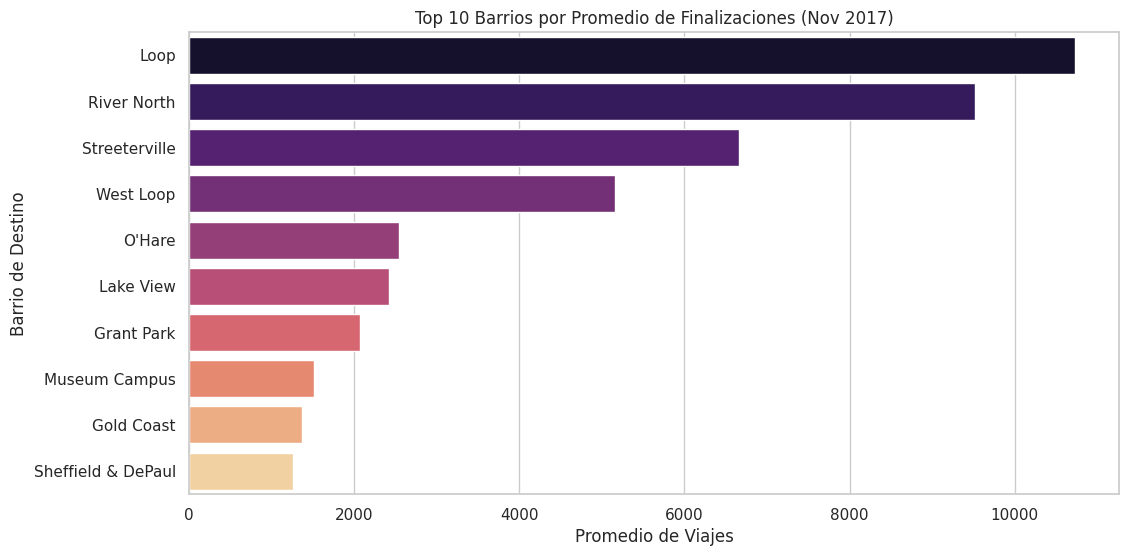

In [12]:
import seaborn as sns
sns.set(style='whitegrid')

# Gráfico de las 10 empresas con más viajes
plt.figure(figsize=(12, 6))
top_companies = df_companies.sort_values(by='trips_amount', ascending=False).head(10)
sns.barplot(data=top_companies, x='trips_amount', y='company_name', palette='viridis')
plt.title('Top 10 Empresas de Taxis por Número de Viajes (15-16 Nov 2017)')
plt.xlabel('Cantidad de Viajes')
plt.ylabel('Empresa')
plt.show()

# Gráfico de los 10 barrios principales
plt.figure(figsize=(12, 6))
sns.barplot(data=top_10_neighborhoods, x='average_trips', y='dropoff_location_name', palette='magma')
plt.title('Top 10 Barrios por Promedio de Finalizaciones (Nov 2017)')
plt.xlabel('Promedio de Viajes')
plt.ylabel('Barrio de Destino')
plt.show()

<div class="alert alert-block alert-success">
<b>Comentario de Revisor            </b> <a class="tocSkip"></a>

¡Muy buen trabajo con la gráfica! Observamos que Flash Cab tiene el liderazgo de cantidad de viajes, bastante más arriba que el competidor que le sigue. Esta concentración de mercado se puede dar por varios factores como cobertura, cantidad de vehículos o buenas estrategias comerciales.

</div>

<div class="alert alert-block alert-success">
<b>Comentario de Revisor            </b> <a class="tocSkip"></a>

¡Buen trabajo obteniendo el top de barrios! El gráfico está ordenado de mayor a menor, lo que permite notar correctamente que Loop Y River North son los principales destinos. Tal vez tienen atractivos importantes que los hacen lugares de muchas visitas.

</div>

Conclusión: Top 10 Empresas de Taxis

Dominio del mercado: La empresa Flash Cab es el líder indiscutible, con casi 20,000 viajes en apenas dos días. Esto es casi el doble que su competidor más cercano, Taxi Affiliation Services.

Concentración: Se observa que el mercado está muy concentrado en las primeras cuatro o cinco empresas. A partir de la quinta posición, la diferencia en la cantidad de viajes se estabiliza, sugiriendo que hay muchas empresas pequeñas compitiendo por el resto del mercado, mientras que Flash Cab posee una infraestructura o base de clientes significativamente mayor.

Explicación: Este volumen masivo para Flash Cab podría deberse a contratos exclusivos con hoteles, una flota mucho más grande o una aplicación móvil más adoptada por los usuarios en Chicago.

Conclusión: Top 10 Barrios de Destino

- Loop y River North son, por mucho, los destinos más frecuentes. Esto confirma que la gran mayoría de los viajes terminan en el corazón financiero, comercial y turístico de la ciudad.

- La presencia de Streeterville y West Loop en los primeros lugares refuerza la idea de que los taxis se mueven principalmente entre zonas de oficinas y puntos turísticos de alta densidad.

- Aunque el aeropuerto (O'Hare) aparece en el quinto lugar en cantidad promedio de viajes, es un destino clave. Es probable que, aunque no tenga el volumen del Loop, sea uno de los destinos que más ingresos genera por viaje debido a la distancia.

- La caída abrupta después del cuarto lugar (West Loop) muestra que Chicago tiene una zona central muy definida donde el taxi es el medio de transporte preferido, mientras que hacia los barrios residenciales como Sheffield & DePaul, el volumen disminuye considerablemente.

- La alta demanda en Loop y River North nos puede dar una explicación de por qué empresas como Flash Cab tienen números tan altos; probablemente concentran su flota en estos puntos estratégicos durante las horas pico

Prueba de Hipotesis 
1. Definición de las Hipótesis
- Hipótesis Nula ($H_0$): La duración promedio de los viajes desde el Loop hasta el Aeropuerto Internacional O'Hare es la misma los sábados lluviosos y los sábados despejados.
- Hipótesis Alternativa ($H_1$): La duración promedio de los viajes desde el Loop hasta el Aeropuerto Internacional O'Hare cambia los sábados lluviosos.
- Nivel de significación ($\alpha$): Estableceremos $\alpha = 0.05$. Esto significa que si hay menos de un 5% de probabilidad de que la diferencia sea por puro azar, rechazaremos la $H_0$.

2. Criterio utilizado
Prueba t de Student para dos muestras independientes (Prueba de Welch). Justificación: 

- Comparación de Medias: El objetivo del proyecto es determinar si el promedio de tiempo cambia. La prueba t es el estándar estadístico para comparar las medias de dos grupos.

- Muestras Independientes: Los viajes realizados en días despejados no afectan ni dependen de los viajes realizados en días lluviosos; son eventos separados.

- Varianza Desigual (equal_var=False): Se utilizó la variante de Welch porque no podemos asumir que la dispersión (varianza) de los tiempos de viaje sea igual en ambos climas. Es muy probable que la lluvia no solo aumente el tiempo, sino que también haga que los tiempos sean más impredecibles (mayor varianza) que en un día soleado.

- Tamaño de la Muestra: Dado que contamos con un conjunto de datos robusto, la distribución de las medias muestrales tiende a ser normal (según el Teorema del Límite Central), lo que valida el uso de esta prueba paramétrica.

In [13]:
from scipy import stats as st 

#Cargar el dataset
df_trips_weather = pd.read_csv('/datasets/project_sql_result_07.csv')

#Filtrar los datos en dos grupos 
good_weather_trips = df_trips_weather[df_trips_weather['weather_conditions'] == 'Good']['duration_seconds']
bad_weather_trips = df_trips_weather[df_trips_weather['weather_conditions'] == 'Bad']['duration_seconds']

#Mostrar las medias para tener una idea incial
print(f"Promedio clima Good: {good_weather_trips.mean():.2f} segundos")
print(f"Promedio clima Bad: {bad_weather_trips.mean():.2f} segundos")

Promedio clima Good: 1999.68 segundos
Promedio clima Bad: 2427.21 segundos


La diferencia es de aproximadamente 7.1 minutos. En el contexto de un viaje al aeropuerto, un aumento del 21% en el tiempo de viaje debido a la lluvia es una diferencia muy significativa para cualquier pasajero o conductor.

In [14]:
#Realizar la prueba t
#Usamos equal_var=False porque no podemos asegurar que las varianzas sean iguales
results = st.ttest_ind(good_weather_trips, bad_weather_trips, equal_var=False)
print('p-value:', results.pvalue)

if results.pvalue < 0.05:
    print("Rechazamos la hipótesis nula")
else: 
    print("No podemos rechazar la hipótesis nula")

p-value: 6.738994326108734e-12
Rechazamos la hipótesis nula


Conclusiones Prueba Hipotesis
1. Resultados Estadísticos
- P-value obtenido: $6.73 \times 10^{-12}$
- Resultado: Rechazamos la hipótesis nula.
2. Análisis de los Datos
Al comparar las medias de ambos grupos, observamos una diferencia clara en los tiempos de traslado:
- Sábados con buen clima: ~1,999.68 segundos (aprox. 33 minutos).
- Sábados con mal clima: ~2,427.21 segundos (aprox. 40 minutos).
3. Conclusión
El análisis estadístico demuestra que existe una diferencia significativa en la duración de los viajes cuando las condiciones climáticas son adversas (lluvia o tormenta). En promedio, un viaje al aeropuerto O'Hare desde el centro de la ciudad toma 7 minutos más (un incremento del 21%) durante un sábado lluvioso en comparación con uno despejado.
Implicaciones:
- Para los pasajeros: Se recomienda planificar sus viajes con al menos 10-15 minutos adicionales de margen en días de lluvia para evitar perder sus vuelos.
- Para la empresa de taxis: Esta información es vital para ajustar los algoritmos de "tiempo estimado de llegada" y optimizar la asignación de conductores, ya que la productividad por hora de cada unidad disminuye moderadamente bajo estas condiciones.

Nota: Aunque una diferencia de 7 minutos puede parecer pequeña en ciudades con congestiones extremas, el valor de $P$ tan extremadamente bajo confirma que este retraso no es fruto del azar, sino un patrón sistemático en la ciudad de Chicago.

<div class="alert alert-block alert-success">
<b>Comentario de Revisor            </b> <a class="tocSkip"></a>

Bien hecho con el test de hipótesis, fue realizado de forma correcta. 

Es importante mencionar que el t-test asume que las dos muestras tienen varianzas iguales. Para verificar esa igualdad de varianzas podemos usar el **test de Levene**. Este nos dice si la variabilidad entre los grupos es estadísticamente diferente. En corto, el flujo sería así

1. Usamos `levene()` para verificar si las varianzas son iguales.
2. Dependiendo del resultado, usamos `ttest_ind()` con el argumento `equal_var`:
   - `equal_var=True` si Levene dice que las varianzas son iguales (p > 0.05).
   - `equal_var=False` si Levene dice que las varianzas son diferentes (p < 0.05).





</div>